# ML Project Pipeline (8 stages) - change ONLY the CONFIG cell

In [ ]:
# !pip -q install optuna shap streamlit
import json, os, warnings, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
from sklearn.datasets import fetch_openml, load_breast_cancer
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_score, GridSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report)
SEED = 42
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)

## CONFIG  (pick ONE project; binary classification only)

In [ ]:
# Select Heart Disease Prediction
# source: "sklearn" or "openml"

# CONFIG = dict(title="Breast Cancer Diagnosis", source="sklearn", data_id=None)

CONFIG = dict(title="Heart Disease Prediction", source="openml", data_id=53)

# Other projects (not selected)
# CONFIG = dict(title="Diabetes Prediction (Pima)", source="openml", data_id=37)
# CONFIG = dict(title="German Credit Risk", source="openml", data_id=31)
# CONFIG = dict(title="Customer Churn Prediction", source="openml", data_id=40701)

## Stage 1 - Data + EDA

shape (270, 13) | classes ['absent', 'present'] | num 13 cat 0
missing %:
 Series([], dtype: float64)
class balance:
 absent     0.556
present    0.444
Name: proportion, dtype: float64


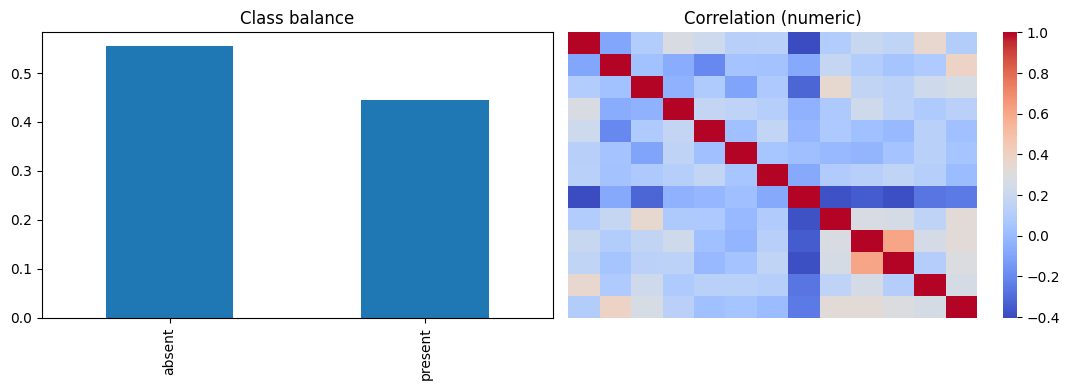

In [ ]:
if CONFIG["source"] == "sklearn":
    df = load_breast_cancer(as_frame=True).frame; target = "target"
else:
    d = fetch_openml(data_id=CONFIG["data_id"], as_frame=True, parser="auto")
    df = d.frame; target = d.target_names[0]
df = df.drop_duplicates().reset_index(drop=True)
le = LabelEncoder(); y = le.fit_transform(df[target].astype(str)); X = df.drop(columns=[target])
assert len(le.classes_) == 2, "binary targets only"
cat_cols = [c for c in X.columns if X[c].dtype.name in ("category", "object", "bool")]
for c in cat_cols: X[c] = X[c].astype(object)
num_cols = [c for c in X.columns if c not in cat_cols]
print("shape", X.shape, "| classes", list(le.classes_), "| num", len(num_cols), "cat", len(cat_cols))
miss = X.isna().mean().sort_values(ascending=False); print("missing %:\n", (miss[miss > 0] * 100).round(1))
bal = pd.Series(y).value_counts(normalize=True).rename(index=dict(enumerate(le.classes_)))
print("class balance:\n", bal.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bal.plot.bar(ax=ax[0], title="Class balance")
sns.heatmap(X[num_cols].corr(), cmap="coolwarm", ax=ax[1], cbar=True, xticklabels=False, yticklabels=False)
ax[1].set_title("Correlation (numeric)"); plt.tight_layout(); plt.savefig("figures/eda.png", dpi=200); plt.show()
X[num_cols].describe().T.round(2).to_csv("results/eda_summary.csv")

## Stage 2 - Stratified split (test set locked until Stage 7)

In [ ]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(Xtr.shape, Xte.shape)

(216, 13) (54, 13)


## Stage 3 - Preprocessing inside a Pipeline (no leakage)

In [ ]:
def make_pre(scale=True, use_cat=True):
    num = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    tr = [("num", Pipeline(num), num_cols)]
    if use_cat and cat_cols:
        tr.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                    ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols))
    return ColumnTransformer(tr)
def make_pipe(model, **kw): return Pipeline([("pre", make_pre(**kw)), ("clf", model)])

## Stage 4 - Baselines, repeated stratified CV (mean ± std)

In [ ]:
models = {
 "Dummy (baseline)": DummyClassifier(strategy="most_frequent"),
 "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
 "KNN": KNeighborsClassifier(),
 "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
 "HistGradBoosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
}
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
rows = []
for n, m in models.items():
    s = cross_validate(make_pipe(m), Xtr, ytr, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": n, **{k: f"{s['test_'+k].mean():.3f} ± {s['test_'+k].std():.3f}" for k in scoring},
                 "_auc": s["test_roc_auc"].mean()})
base = pd.DataFrame(rows).sort_values("_auc", ascending=False)
best_name = base[base.Model != "Dummy (baseline)"].iloc[0].Model
base.drop(columns="_auc").to_csv("results/baselines.csv", index=False)
print(base.drop(columns="_auc").to_string(index=False)); print("BEST:", best_name)

             Model      accuracy     precision        recall            f1       roc_auc
LogisticRegression 0.822 ± 0.059 0.802 ± 0.085 0.812 ± 0.105 0.802 ± 0.067 0.906 ± 0.052
      RandomForest 0.836 ± 0.068 0.847 ± 0.102 0.784 ± 0.114 0.808 ± 0.083 0.901 ± 0.057
  HistGradBoosting 0.798 ± 0.086 0.788 ± 0.120 0.770 ± 0.082 0.774 ± 0.086 0.897 ± 0.061
               KNN 0.830 ± 0.056 0.839 ± 0.081 0.774 ± 0.104 0.800 ± 0.070 0.895 ± 0.044
  Dummy (baseline) 0.556 ± 0.005 0.000 ± 0.000 0.000 ± 0.000 0.000 ± 0.000 0.500 ± 0.000
BEST: LogisticRegression


## Stage 5 - Tuning: GridSearch + NESTED CV

In [ ]:
grids = {
 "LogisticRegression": {"clf__C": [0.01, 0.1, 1, 10, 100]},
 "KNN": {"clf__n_neighbors": [3, 5, 9, 15], "clf__weights": ["uniform", "distance"]},
 "RandomForest": {"clf__max_depth": [None, 5, 10], "clf__min_samples_leaf": [1, 3, 5]},
 "HistGradBoosting": {"clf__learning_rate": [0.03, 0.1], "clf__max_depth": [None, 3, 6]},
}
inner = StratifiedKFold(3, shuffle=True, random_state=SEED)
outer = StratifiedKFold(5, shuffle=True, random_state=SEED)
gs = GridSearchCV(make_pipe(models[best_name]), grids[best_name], cv=inner, scoring="roc_auc", n_jobs=-1)
nested = cross_val_score(gs, Xtr, ytr, cv=outer, scoring="roc_auc")
print(f"Nested-CV ROC-AUC: {nested.mean():.3f} ± {nested.std():.3f}")
gs.fit(Xtr, ytr); final = gs.best_estimator_
print("Best params:", gs.best_params_)
json.dump({"model": best_name, "best_params": {k: str(v) for k, v in gs.best_params_.items()},
           "nested_auc_mean": nested.mean(), "nested_auc_std": nested.std()}, open("results/tuning.json", "w"), indent=2)

Nested-CV ROC-AUC: 0.906 ± 0.038
Best params: {'clf__C': 0.01}


## Stage 6 - Ablation (remove one component at a time; CV on TRAIN only)

In [ ]:
def cv_auc(pipe):
    s = cross_val_score(pipe, Xtr, ytr, cv=cv, scoring="roc_auc", n_jobs=-1)
    return f"{s.mean():.3f} ± {s.std():.3f}"
bp = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
def tuned(**kw):
    m = clone(models[best_name]).set_params(**bp); return make_pipe(m, **kw)
ab = [("Full tuned pipeline", cv_auc(tuned())),
      ("- no scaling", cv_auc(tuned(scale=False))),
      ("- default hyperparameters", cv_auc(make_pipe(clone(models[best_name]))))]
if cat_cols: ab.append(("- no categorical features", cv_auc(tuned(use_cat=False))))
if "class_weight" in models[best_name].get_params():
    ab.append(("- no class weighting", cv_auc(make_pipe(clone(models[best_name]).set_params(**bp, class_weight=None)))))
abl = pd.DataFrame(ab, columns=["Variant", "ROC-AUC (mean ± std)"])
abl.to_csv("results/ablation.csv", index=False); print(abl.to_string(index=False))

                  Variant ROC-AUC (mean ± std)
      Full tuned pipeline        0.913 ± 0.048
             - no scaling        0.860 ± 0.045
- default hyperparameters        0.906 ± 0.052
     - no class weighting        0.914 ± 0.047


## Stage 7 - Test evaluation (ONCE)

{'accuracy': 0.833, 'precision': 0.778, 'recall': 0.875, 'f1': 0.824, 'roc_auc': np.float64(0.91)}
              precision    recall  f1-score   support

      absent       0.89      0.80      0.84        30
     present       0.78      0.88      0.82        24

    accuracy                           0.83        54
   macro avg       0.83      0.84      0.83        54
weighted avg       0.84      0.83      0.83        54



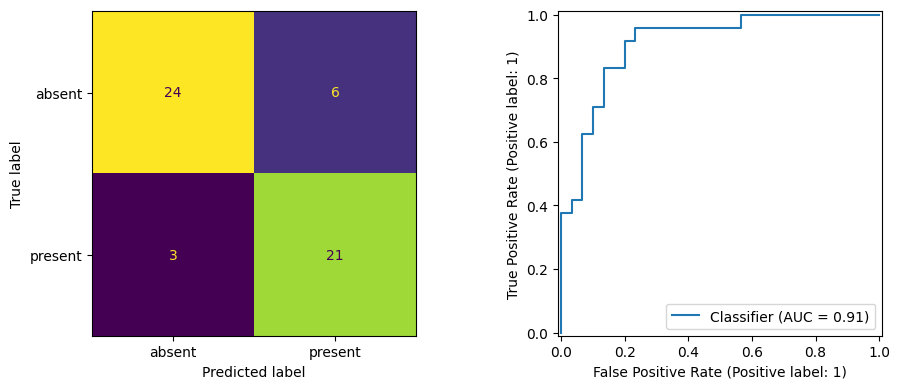

9 misclassified of 54 -> see results/errors.csv


In [ ]:
pred = final.predict(Xte); prob = final.predict_proba(Xte)[:, 1]
test = {"accuracy": accuracy_score(yte, pred), "precision": precision_score(yte, pred), "recall": recall_score(yte, pred),
        "f1": f1_score(yte, pred), "roc_auc": roc_auc_score(yte, prob)}
print({k: round(v, 3) for k, v in test.items()})
print(classification_report(yte, pred, target_names=[str(c) for c in le.classes_]))
json.dump(test, open("results/test_metrics.json", "w"), indent=2)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=le.classes_).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(yte, prob, ax=ax[1]); plt.tight_layout()
plt.savefig("figures/test_eval.png", dpi=200); plt.show()
err = Xte[pred != yte].copy(); err["true"] = le.classes_[yte[pred != yte]]; err["pred"] = le.classes_[pred[pred != yte]]
err.to_csv("results/errors.csv")
print(len(err), "misclassified of", len(yte), "-> see results/errors.csv")

## Stage 8 - Explainability + save model for the app

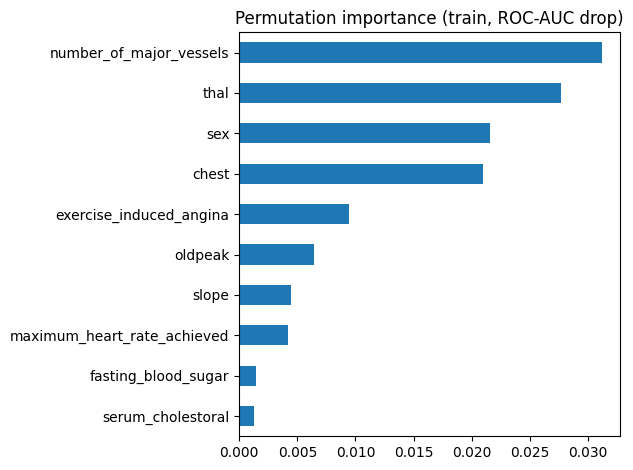

saved model.joblib + meta.json  -> download with files.download in Colab


In [ ]:
pi = permutation_importance(final, Xtr, ytr, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values().tail(10)
imp.plot.barh(title="Permutation importance (train, ROC-AUC drop)"); plt.tight_layout()
plt.savefig("figures/importance.png", dpi=200); plt.show()
feats = {}
for c in X.columns:
    feats[c] = ({"type": "cat", "cats": sorted(map(str, X[c].dropna().unique()))} if c in cat_cols else
                {"type": "num", "min": float(X[c].min()), "max": float(X[c].max()), "median": float(X[c].median())})
joblib.dump(final, "model.joblib")
meta = {"title": CONFIG["title"], "classes": [str(c) for c in le.classes_], "features": feats}
json.dump(meta, open("meta.json", "w"), indent=2)
print("saved model.joblib + meta.json  -> download with files.download in Colab")

In [ ]:
from google.colab import files
import shutil

shutil.make_archive(
    "Heart_Disease_Project",
    "zip",
    "."
)

files.download("Heart_Disease_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')